# Assignment 3 — Association Rule Mining

**Dataset:** `bread_basket.csv` (11569 transactions)

Fill in the short answer cells and run the code cells. This notebook generates the required tables and figures.

**Sections:**
1. Setup & Data Load
2. EDA (a–e)
3. Frequent Itemset Mining (FP-Growth)
4. Association Rules + Report Table
5. Rule Subgraph (Bread, Coffee, Cake, Tea)
6. Interpretation Prompt


## 1) Setup & Data Load (10 pts)
- Place `bread_basket.csv` in the same folder as this notebook **or** update the path below.
- Needed packages: `pandas`, `matplotlib`, `mlxtend`, `networkx` (for the small graph).
- If a package is missing, run the `pip install` cell.

In [66]:
 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

CSV_PATH = "bread_basket.csv"
bread = pd.read_csv(CSV_PATH)

basket = (bread.groupby('transaction')['item'].apply(list)
                 .reset_index()
                 .sort_values('transaction')['item']
                 .tolist())





## 2) EDA (a–e) (30 pts)
### a) List variables and their dtypes (5 pts)

In [67]:
bread.dtypes

transaction        int64
item                 str
date_time            str
time                 str
period_day           str
weekday_weekend      str
dtype: object

### b) "Statistics" overview (5 pts)
Use `describe(include='all')` as a stand‑in for Statistics.

In [68]:
bread.describe(include='all')

,transaction,item,date_time,time,period_day,weekday_weekend
count,20507.000000,20507,20507,20507,20507,20507
unique,NaN,94,159,1255,4,2
top,NaN,Coffee,2017-02-04,11:06,afternoon,weekday
freq,NaN,5471,292,52,11569,12807
mean,4976.202370,NaN,NaN,NaN,NaN,NaN
std,2796.203001,NaN,NaN,NaN,NaN,NaN
min,1.000000,NaN,NaN,NaN,NaN,NaN
25%,2552.000000,NaN,NaN,NaN,NaN,NaN
50%,5137.000000,NaN,NaN,NaN,NaN,NaN
75%,7357.000000,NaN,NaN,NaN,NaN,NaN


### c) Bar plot — count of **unique transactions per item** (10 pts)
Set the subtitle to your **FirstName LastName**.

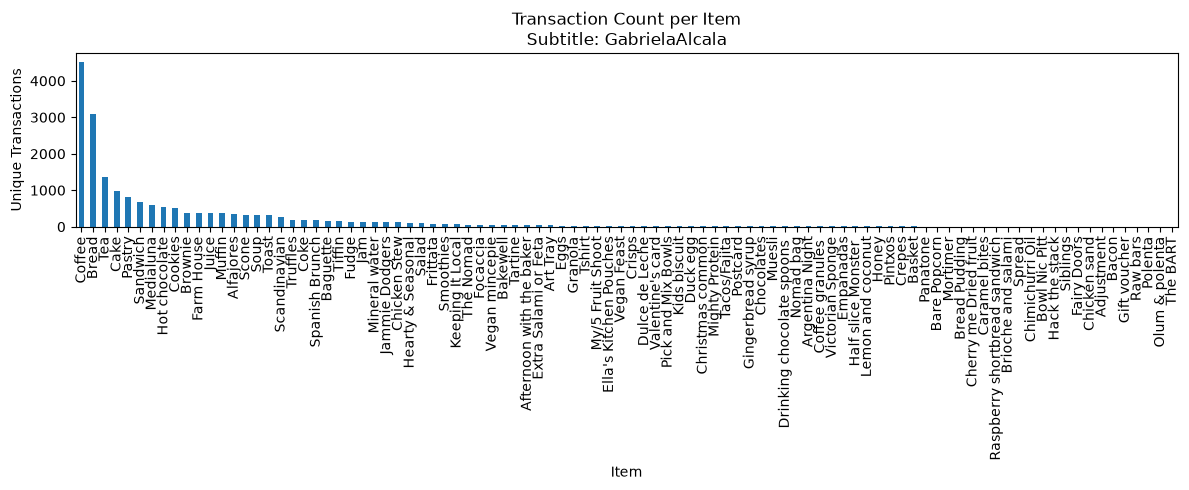

In [69]:
# c) Bar plot of transaction counts per item
subtitle = "GabrielaAlcala"  # <-- EDIT THIS
item_counts = (bread.groupby('item')['transaction'].nunique()
                 .sort_values(ascending=False))

ax = item_counts.plot(kind='bar', figsize=(12,5))
plt.title(f"Transaction Count per Item\nSubtitle: {subtitle}")
plt.xlabel("Item"); plt.ylabel("Unique Transactions")
plt.tight_layout()
plt.show()

### d) Report counts for Coffee, Tea, Alfajores, Juice, and Chicken Stew (10 pts)

In [70]:
report_counts = [
    "Coffee", "Tea", "Alfajores", "Juice", "Chicken Stew"
    ]

print(item_counts.loc[report_counts])

item
Coffee          4528
Tea             1350
Alfajores        344
Juice            365
Chicken Stew     123
Name: transaction, dtype: int64


## 3) Frequent Itemset Mining with FP‑Growth (min_support = 0.02) (20 pts)
We pivot the data to a **transaction × item** one‑hot table (boolean), then run FP‑Growth.

In [71]:
te_b = TransactionEncoder()
oht_b = pd.DataFrame(te_b.fit(basket).transform(basket), columns=te_b.columns_).astype(bool)
oht_b.head()


,Adjustment,Afternoon with the baker,Alfajores,Argentina Night,Art Tray,Bacon,Baguette,Bakewell,Bare Popcorn,Basket,...,The BART,The Nomad,Tiffin,Toast,Truffles,Tshirt,Valentine's card,Vegan Feast,Vegan mincepie,Victorian Sponge
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [74]:
frequent_itemsets = fpgrowth(
    oht_b,
    min_support=0.02,
    use_colnames=True
)

frequent_itemsets = frequent_itemsets.sort_values(
    "support",
    ascending=False
)

frequent_itemsets

,support,itemsets
5,0.478394,frozenset({Coffee})
0,0.327205,frozenset({Bread})
8,0.142631,frozenset({Tea})
12,0.103856,frozenset({Cake})
19,0.090016,"frozenset({Coffee, Bread})"
6,0.086107,frozenset({Pastry})
13,0.071844,frozenset({Sandwich})
7,0.061807,frozenset({Medialuna})
2,0.058320,frozenset({Hot chocolate})
28,0.054728,"frozenset({Coffee, Cake})"


## 4) Association Rules + Report Table (30 pts)
(metric = confidence, min_threshold = ?) Please find a suitable min_threshold

In [81]:
assoc_rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.1)
assoc_rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']].sort_values('confidence', ascending=False)

,antecedents,consequents,support,confidence,lift
15,frozenset({Toast}),frozenset({Coffee}),0.023666,0.704403,1.472431
8,frozenset({Medialuna}),frozenset({Coffee}),0.035182,0.569231,1.189878
6,frozenset({Pastry}),frozenset({Coffee}),0.047544,0.552147,1.154168
17,frozenset({Juice}),frozenset({Coffee}),0.020602,0.534247,1.116750
7,frozenset({Sandwich}),frozenset({Coffee}),0.038246,0.532353,1.112792
3,frozenset({Cake}),frozenset({Coffee}),0.054728,0.526958,1.101515
11,frozenset({Cookies}),frozenset({Coffee}),0.028209,0.518447,1.083723
9,frozenset({Hot chocolate}),frozenset({Coffee}),0.029583,0.507246,1.060311
5,frozenset({Tea}),frozenset({Coffee}),0.049868,0.349630,0.730840
10,frozenset({Pastry}),frozenset({Bread}),0.029160,0.338650,1.034977


## 5) Interpretation (10 pts)
**Interpret the rule `{Coffee, Cake} ⇒ {Bread}` in plain English.**

- **Support**: What fraction of *all* transactions contain Coffee, Cake, and Bread together?
- **Confidence**: Among baskets with Coffee and Cake, what share also include Bread?
- **Lift > 1** implies positive association; comment on practical meaning.

*Your notes:* (write your answer here)

I could not figure out how to show the Coffee, Cake, and Bread together. 

If lift is greater than 1 that means the items associated are more than likely to sell together. The greater it is than 1, the more likely. 



>